# 02 · Behavior Classification

**Research questions**
1. Can we predict which behavior a mouse will choose on a trial (**Eat, Carry, NosePoke, NoLeave**) from the task conditions and the information available *before* the trial?
2. Do these predictions generalize to **mice the model has never seen**?
3. Are the predictive relationships different in **Control** and **AD** mice?

## Only information available *before* the decision

Every model in this notebook is **prospective**: it uses only information that exists before the behavior happens. One trial contains **two decisions in sequence**, and each decision has its own set of valid predictors (notebook 01, section 2.5):

| Decision | When | Valid predictors |
|---|---|---|
| **1. Leave home or stay?** | at gate opening | task parameters, previous trial, experience |
| **2. At the food: Eat, Carry or NosePoke?** | when the mouse reaches the food | the above **+ how the mouse approached**: `DelayToStart`, `InitialVelOut` |

Sections 1–8 predict all four behaviors with the predictors of decision 1. Section 9 focuses on decision 2 and asks whether the approach behavior adds information.

Variables measured **during or after** the eat/carry/poke behavior (`AtFoodArea`, `BackAndForth`, `InboundVel`, `InitialVelIn`) and `OutboundVel` (averaged over *all* outbound trips, including those after the first food encounter) are **not used in any model** here. They are partly consequences of the behavior, so using them would be target leakage.

## Plan of this notebook
1. Load data and define the feature sets
2. How we validate: leave-one-mouse-out with nested tuning
3. How we measure performance
4. Step 1 – task parameters only
5. Step 2 – adding behavioral history and experience
6. Step 3 – more flexible models
7. A closer look at the best model: per class, per mouse
8. Comparing Control and AD (fair sample size, cross-group transfer, probabilities)
9. The food-site decision: does the approach behavior add information?
10. Save results
11. Summary

## 0. Setup

New helper modules (open them in `src/` to read the code):
* `src/modeling.py` – builds each model as a **Pipeline** (preprocessing → classifier) together with a small grid of hyperparameters to try.
* `src/evaluation.py` – leave-one-mouse-out evaluation, metrics, and bootstrap confidence intervals over mice.

Running the whole notebook takes about 10–15 minutes, mostly for the random forest.

In [1]:
import sys
sys.path.insert(0, "..")

import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import modeling, evaluation
from src import visualization as viz

viz.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
# Some held-out mice never show one of the four behaviors; sklearn then warns
# that a metric is undefined for that class. The warnings are expected.
warnings.filterwarnings("ignore", category=UserWarning)

CLASSES = viz.BEHAVIOR_ORDER          # ["Eat", "Carry", "NosePoke", "NoLeave"]
TABLES = "../results/tables"
import os
os.makedirs(TABLES, exist_ok=True)

## 1. Data and feature sets

**Goal:** load the clean table from notebook 01 and define which columns the models may use.

We build the prospective feature sets **step by step**, so that we can measure what each kind of information adds:

| Feature set | Columns | Type |
|---|---|---|
| **Task** | `Length`, `Texture`, `SizeCategory` | categorical (set by the experimenter) |
| **+ History** | `PrevBehavior` (outcome of the previous trial in the session), `TrialInSession` (1–4) | categorical, numeric |
| **+ Experience** | `SessionInCondition` (sessions already done in the current condition block) | numeric |

We do **not** use `Id` (the model must work for new mice), `Sex` (not a research question here, and only 13 AD mice), or `SessionNumber` (strongly tied to the condition order, see notebook 01, section 3.5).

In [2]:
df = pd.read_csv("../data/processed/trials_clean.csv")

TASK = ["Length", "Texture", "SizeCategory"]
FEATURE_SETS = {
    "Task":                     {"categorical": TASK,                      "numeric": []},
    "Task + History":           {"categorical": TASK + ["PrevBehavior"],   "numeric": ["TrialInSession"]},
    "Task + History + Experience": {"categorical": TASK + ["PrevBehavior"], "numeric": ["TrialInSession", "SessionInCondition"]},
}

data_by_group = {group: df[df["Status"] == group].copy() for group in viz.GROUP_ORDER}

for group, data in data_by_group.items():
    counts = data["Behavior"].value_counts().reindex(CLASSES)
    print(f"{group:8s} {data['Id'].nunique()} mice, {len(data)} trials | " +
          ", ".join(f"{b}: {n} ({n / len(data):.0%})" for b, n in counts.items()))

Control  28 mice, 3425 trials | Eat: 2030 (59%), Carry: 610 (18%), NosePoke: 567 (17%), NoLeave: 218 (6%)
AD       13 mice, 1952 trials | Eat: 1240 (64%), Carry: 207 (11%), NosePoke: 298 (15%), NoLeave: 207 (11%)


**How to read the output:** the two groups are modeled **separately**. Each model sees only Control mice or only AD mice. This lets us compare *how well* behavior can be predicted in each group and *which relationships* the models learn. Note the different sample sizes: about 3,400 Control trials from 28 mice vs. about 2,000 AD trials from 13 mice.

## 2. How we validate: leave-one-mouse-out with nested tuning

### 2.1 Why mice, not trials, must be held out

A model is useful only if it works for **new animals**. If trials of the same mouse appear in both the training and the test set, the model can partly recognize *the mouse* (its habits) instead of learning general rules. The test score then overestimates how well the model generalizes. The original notebook used `train_test_split` on trials, which has this problem.

Below we compare, for the same random-forest model:
* **trial-level 5-fold CV** (`StratifiedKFold`): trials are shuffled, so each mouse is in both training and test folds;
* **mouse-level 5-fold CV** (`GroupKFold`): all trials of a mouse are in the same fold.

To make the effect visible we add `SessionNumber`, a feature that helps identify a mouse (mice differ in their total number of sessions).

In [3]:
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_score

demo_categorical = TASK + ["PrevBehavior"]
demo_numeric = ["TrialInSession", "SessionInCondition", "SessionNumber"]
demo_features = demo_categorical + demo_numeric

for group in viz.GROUP_ORDER:
    data = data_by_group[group]
    forest, _ = modeling.make_model("Random forest", demo_categorical, demo_numeric)
    forest.set_params(classifier__min_samples_leaf=1, classifier__n_jobs=-1)

    trial_level = cross_val_score(forest, data[demo_features], data["Behavior"],
                                  cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
                                  scoring="balanced_accuracy")
    mouse_level = cross_val_score(forest, data[demo_features], data["Behavior"],
                                  cv=GroupKFold(n_splits=5), groups=data["Id"],
                                  scoring="balanced_accuracy")
    print(f"{group:8s} balanced accuracy | trial-level CV: {trial_level.mean():.3f}   "
          f"mouse-level CV: {mouse_level.mean():.3f}")

Control  balanced accuracy | trial-level CV: 0.440   mouse-level CV: 0.420


AD       balanced accuracy | trial-level CV: 0.437   mouse-level CV: 0.414


**How to read the output:** the trial-level score is somewhat higher than the mouse-level score. The difference is modest **here** because our features carry little information about *which* mouse a trial came from. It becomes dramatic when features identify the animal, as in notebook 03 (classifying the *mouse's* group). Either way, the correct question for science is "does it work on a new mouse?", so **all** evaluations below hold out entire mice.

### 2.2 Leave-one-mouse-out (LOMO)

With only 13 AD mice, we use the most data-efficient mouse-level scheme: **each mouse is the test set once**.

```
for each mouse M:
    training data = all other mice
    tune hyperparameters using ONLY the training mice      (inner loop)
    fit the model on the training mice
    predict every trial of mouse M                          (outer loop)
```

After the loop every trial has one **out-of-fold prediction**, made by a model that never saw that mouse. All metrics are computed from these predictions.

### 2.3 Nested cross-validation: keeping tuning honest

Hyperparameters (e.g. the regularization strength of logistic regression, the depth of a tree) are chosen by trying several values and keeping the best. If we chose them using the test mouse, the test score would be optimistically biased: we would have "peeked". So the tuning happens **inside** the training mice, with its own grouped 5-fold cross-validation (inner loop). This is **nested cross-validation**:
* **outer loop** (LOMO): estimates performance on new mice;
* **inner loop** (`GroupKFold` on training mice): selects hyperparameters.

Here is the function that does this:

In [4]:
print(inspect.getsource(evaluation.leave_one_mouse_out))

def leave_one_mouse_out(model, grid, data, features, target, classes, inner_splits=5):
    """Out-of-fold predictions with leave-one-mouse-out (outer loop) and
    grouped cross-validation for hyperparameter tuning (inner loop).

    This is NESTED cross-validation:
      - the outer loop estimates performance on unseen mice;
      - the inner loop (GroupKFold over the training mice only) chooses
        hyperparameters. The test mouse is never used for tuning.

    Returns a DataFrame with one row per trial: Id, true label, predicted
    label, one probability column per class, and the chosen hyperparameters.
    """
    results = []
    for test_mouse in data["Id"].unique():
        is_test = data["Id"] == test_mouse
        train = data[~is_test]
        test = data[is_test]

        if grid:
            search = GridSearchCV(
                clone(model), grid,
                cv=GroupKFold(n_splits=inner_splits),
                scoring="balanced_accuracy",
                n_jobs=

**Important details in this code:**
* `clone(model)` creates a fresh, unfitted copy for every fold, so nothing learned from one fold leaks into the next.
* `GridSearchCV(..., cv=GroupKFold(...))` with `groups=train["Id"]` keeps the inner folds mouse-level too.
* Preprocessing (one-hot encoding, scaling) is part of the pipeline, so it is **re-fitted on the training mice in every fold**. This is the leakage-safe way to preprocess.
* **Class imbalance** is handled with `class_weight="balanced"` inside the classifier. Errors on rare classes (NoLeave, Carry) cost more during training. This acts like resampling, but it never creates or deletes data, and it automatically uses only the training fold. We avoid SMOTE-style oversampling: synthetic trials built from categorical features would just duplicate existing trials.

## 3. How we measure performance

| Metric | Meaning | Chance level (4 classes) |
|---|---|---|
| **Balanced accuracy** | average of the recall of each class: "what fraction of Eat trials were called Eat, of Carry trials called Carry, …", averaged | 0.25 |
| **Macro-F1** | average F1 over classes. F1 combines precision ("when the model says Carry, how often is it Carry?") and recall | ≈ 0.19–0.25 depending on class balance |
| **Log loss** | how much probability the model put on the true class. **Lower is better.** It judges the *probabilities*, not just the final answer | value of the class-frequency baseline |

Plain accuracy is **not** used. Because ~60 % of trials are Eat, a model that always says "Eat" would have 60 % accuracy while being useless.

**Uncertainty:** the score depends on *which* mice happen to be in the study. We estimate this with a **bootstrap over mice**: draw 13 (or 28) mice *with replacement*, recompute the score, repeat 1,000 times, and report the middle 95 % of the results as a confidence interval (CI). Resampling **mice** rather than trials respects the fact that the mouse is the independent unit.

In [5]:
def evaluate(model_name, feature_set_name, group, n_bootstrap=1000):
    # Run LOMO for one model / feature set / group and summarize it.
    features = FEATURE_SETS[feature_set_name]
    pipeline, grid = modeling.make_model(model_name, features["categorical"], features["numeric"])
    predictions = evaluation.leave_one_mouse_out(
        pipeline, grid, data_by_group[group],
        features["categorical"] + features["numeric"], "Behavior", CLASSES)

    scores = evaluation.summary_metrics(predictions, CLASSES)
    boot = evaluation.bootstrap_over_mice(predictions, CLASSES, n_bootstrap=n_bootstrap)
    row = {"group": group, "features": feature_set_name, "model": model_name}
    for metric in ["balanced_accuracy", "macro_F1", "log_loss"]:
        row[metric] = scores[metric]
        row[metric + "_CI"] = f"[{boot[metric].quantile(0.025):.2f}, {boot[metric].quantile(0.975):.2f}]"
    return row, predictions


all_rows = []          # one summary row per evaluation
all_predictions = {}   # out-of-fold predictions, keyed by (group, features, model)


def run(model_name, feature_set_name, group):
    row, predictions = evaluate(model_name, feature_set_name, group)
    all_rows.append(row)
    all_predictions[(group, feature_set_name, model_name)] = predictions
    return row


def show(rows):
    table = pd.DataFrame(rows)
    columns = ["group", "features", "model", "balanced_accuracy", "balanced_accuracy_CI",
               "macro_F1", "macro_F1_CI", "log_loss", "log_loss_CI"]
    return table[columns].round(3)

## 4. Step 1 – Task parameters only

**Goal:** how much of the behavior is explained by the three experimental variables alone?

**Models:**
* **Baseline (class frequencies)** always predicts the class proportions of the training mice. Any useful model must beat it.
* **Multinomial logistic regression**: for each behavior it learns a weighted sum of the features, and converts the four sums into probabilities that add up to 1 (the *softmax*). It is our main model because it is simple, fast, hard to overfit, and its coefficients can be interpreted (notebook 04). With only main effects it cannot represent **interactions** (e.g. "size matters more when the distance is long"). Tree models in section 6 can.

In [6]:
step1 = []
for group in viz.GROUP_ORDER:
    step1.append(run("Baseline (class frequencies)", "Task", group))
    step1.append(run("Logistic regression", "Task", group))
show(step1)

,group,features,model,balanced_accuracy,balanced_accuracy_CI,macro_F1,macro_F1_CI,log_loss,log_loss_CI
0,Control,Task,Baseline (class frequencies),0.250,"[0.25, 0.25]",0.186,"[0.17, 0.20]",1.114,"[0.99, 1.24]"
1,Control,Task,Logistic regression,0.416,"[0.36, 0.46]",0.389,"[0.33, 0.44]",1.282,"[1.25, 1.31]"
2,AD,Task,Baseline (class frequencies),0.250,"[0.25, 0.25]",0.194,"[0.17, 0.21]",1.105,"[0.92, 1.30]"
3,AD,Task,Logistic regression,0.405,"[0.37, 0.44]",0.311,"[0.24, 0.37]",1.278,"[1.23, 1.32]"


**How to read the output:**
* The baseline has a balanced accuracy of exactly 0.25 (chance), as expected.
* With only the three task parameters, logistic regression reaches a balanced accuracy of **~0.41 in both groups**. That is clearly above chance (the CIs do not include 0.25). The task conditions carry real but limited information about the behavior.
* Macro-F1 is lower in AD (0.31 vs 0.39). With task parameters alone, the AD model struggles more with some classes (section 7 shows which).
* **Log loss is *worse* than the baseline** (1.28 vs 1.11). This is not a bug: the class weights distort the predicted probabilities. Section 8.3 explains this and fixes it.

**Why can't the task alone do better?** There are only 2 × 2 × 2 = 8 possible task situations, so the model can only output 8 different predictions. Within one situation, mice still show all four behaviors, partly because mice differ from each other (notebook 01). The *ceiling* for any task-only model is therefore low, whatever algorithm is used.

## 5. Step 2 – Adding behavioral history and experience

**Goal:** does knowing what happened *before* the trial improve prediction? Notebook 01 showed that behaviors tend to repeat (section 8), so we expect `PrevBehavior` to help.

In [7]:
step2 = []
for group in viz.GROUP_ORDER:
    step2.append(run("Logistic regression", "Task + History", group))
    step2.append(run("Logistic regression", "Task + History + Experience", group))
show(step1[1::2] + step2)

,group,features,model,balanced_accuracy,balanced_accuracy_CI,macro_F1,macro_F1_CI,log_loss,log_loss_CI
0,Control,Task,Logistic regression,0.416,"[0.36, 0.46]",0.389,"[0.33, 0.44]",1.282,"[1.25, 1.31]"
1,AD,Task,Logistic regression,0.405,"[0.37, 0.44]",0.311,"[0.24, 0.37]",1.278,"[1.23, 1.32]"
2,Control,Task + History,Logistic regression,0.431,"[0.40, 0.45]",0.378,"[0.34, 0.41]",1.207,"[1.18, 1.24]"
3,Control,Task + History + Experience,Logistic regression,0.450,"[0.42, 0.47]",0.398,"[0.36, 0.43]",1.205,"[1.18, 1.23]"
4,AD,Task + History,Logistic regression,0.466,"[0.40, 0.51]",0.390,"[0.32, 0.44]",1.180,"[1.14, 1.22]"
5,AD,Task + History + Experience,Logistic regression,0.482,"[0.44, 0.51]",0.402,"[0.33, 0.45]",1.185,"[1.15, 1.22]"


### Is the improvement real? A paired comparison

The confidence intervals of two models overlap a lot, but that does not mean the difference is uncertain. Both models are tested on the **same mice**, and mice that are hard for one model are usually hard for the other. A **paired bootstrap** uses this: in each repetition it draws one set of mice and computes the *difference* in macro-F1 between the two models on exactly those mice.

In [8]:
comparisons = [
    ("Task", "Task + History"),
    ("Task + History", "Task + History + Experience"),
]
paired_rows = []
for group in viz.GROUP_ORDER:
    for set_a, set_b in comparisons:
        pred_a = all_predictions[(group, set_a, "Logistic regression")]
        pred_b = all_predictions[(group, set_b, "Logistic regression")]
        diff = evaluation.paired_bootstrap_difference(pred_a, pred_b, CLASSES, metric="macro_F1")
        paired_rows.append({
            "group": group, "comparison": f"{set_b}  vs  {set_a}",
            "mean difference in macro-F1": diff.mean(),
            "95% CI": f"[{np.quantile(diff, 0.025):+.3f}, {np.quantile(diff, 0.975):+.3f}]",
            "fraction of bootstraps > 0": (diff > 0).mean(),
        })
pd.DataFrame(paired_rows).round(3)

,group,comparison,mean difference in macro-F1,95% CI,fraction of bootstraps > 0
0,Control,Task + History vs Task,-0.010,"[-0.045, +0.027]",0.320
1,Control,Task + History + Experience vs Task + History,0.019,"[+0.010, +0.029]",1.000
2,AD,Task + History vs Task,0.073,"[+0.026, +0.116]",1.000
3,AD,Task + History + Experience vs Task + History,0.013,"[-0.006, +0.037]",0.884


**How to read the output:**
* **AD:** adding history clearly helps: macro-F1 improves by +0.07 (95 % CI +0.03 to +0.12; positive in 100 % of bootstraps). In AD mice, the previous outcome carries substantial information about the next one. This fits notebook 01: NoLeave is "sticky" and often follows Carry, and NoLeave is more frequent in AD mice.
* **Control:** adding history does **not** improve macro-F1 (−0.01, CI includes 0), although balanced accuracy (0.416 → 0.431) and log loss (1.28 → 1.21) improve slightly. In Control mice, history adds less beyond the task conditions.
* **Experience** (`SessionInCondition`) adds a small but consistent gain in Control (+0.02, CI excludes 0) and a similar, less certain gain in AD (+0.01, CI includes 0).

**Interpretation:** history is more informative for AD mice than for Control mice. This is a *predictive* statement. One possible explanation is that AD behavior depends more on the animal's current state, for example a run of NoLeave trials. But this analysis cannot show *why*. Remember also that `PrevBehavior` partly carries information about *which mouse* it is (mice that often NoLeave have many NoLeave → NoLeave transitions).

## 6. Step 3 – More flexible models

**Goal:** can models that capture interactions and non-linear effects do better than logistic regression on the full prospective feature set?

| Model | Idea | Key hyperparameters tuned (inner loop) |
|---|---|---|
| **Decision tree** | a sequence of yes/no questions ("Is the pellet large? Was the previous trial Carry?") | `max_depth`, `min_samples_leaf` |
| **Random forest** | average of many trees, each grown on a bootstrap sample with random feature subsets; reduces the variance of a single tree | `max_depth`, `min_samples_leaf` |
| **Gradient boosting** (`HistGradientBoostingClassifier`, the scikit-learn equivalent of XGBoost) | trees added one after another, each correcting the errors of the previous ones | `learning_rate`, `max_depth` |

We skip **KNN** and **SVM** (both in the original notebook). Our predictors are mostly categorical (one-hot 0/1 columns), and distance-based methods such as KNN are poorly suited to such data. They also offer no interpretability advantage.

In [9]:
step3 = []
for group in viz.GROUP_ORDER:
    for model_name in ["Decision tree", "Random forest", "Gradient boosting"]:
        step3.append(run(model_name, "Task + History + Experience", group))
show([r for r in step2 if r["features"] == "Task + History + Experience"] + step3)

,group,features,model,balanced_accuracy,balanced_accuracy_CI,macro_F1,macro_F1_CI,log_loss,log_loss_CI
0,Control,Task + History + Experience,Logistic regression,0.450,"[0.42, 0.47]",0.398,"[0.36, 0.43]",1.205,"[1.18, 1.23]"
1,AD,Task + History + Experience,Logistic regression,0.482,"[0.44, 0.51]",0.402,"[0.33, 0.45]",1.185,"[1.15, 1.22]"
2,Control,Task + History + Experience,Decision tree,0.441,"[0.40, 0.48]",0.397,"[0.35, 0.44]",1.280,"[1.21, 1.38]"
3,Control,Task + History + Experience,Random forest,0.445,"[0.42, 0.47]",0.393,"[0.35, 0.43]",1.202,"[1.18, 1.23]"
4,Control,Task + History + Experience,Gradient boosting,0.444,"[0.42, 0.47]",0.401,"[0.36, 0.43]",1.184,"[1.16, 1.21]"
5,AD,Task + History + Experience,Decision tree,0.473,"[0.42, 0.52]",0.393,"[0.33, 0.45]",1.591,"[1.32, 1.90]"
6,AD,Task + History + Experience,Random forest,0.478,"[0.42, 0.52]",0.391,"[0.32, 0.45]",1.182,"[1.14, 1.21]"
7,AD,Task + History + Experience,Gradient boosting,0.495,"[0.44, 0.54]",0.409,"[0.33, 0.47]",1.144,"[1.09, 1.19]"


In [10]:
# Which hyperparameters did the inner loop choose? If the choice changes a lot
# from one held-out mouse to the next, the tuning is unstable.
for group in viz.GROUP_ORDER:
    for model_name in ["Logistic regression", "Random forest", "Gradient boosting"]:
        chosen = all_predictions[(group, "Task + History + Experience", model_name)]
        per_mouse_choice = chosen.groupby("Id")["hyperparameters"].first()
        print(f"{group:8s} {model_name:20s}", per_mouse_choice.value_counts().to_dict())

Control  Logistic regression  {"{'classifier__C': 0.1}": 17, "{'classifier__C': 1}": 5, "{'classifier__C': 10}": 3, "{'classifier__C': 0.01}": 3}
Control  Random forest        {"{'classifier__max_depth': 4, 'classifier__min_samples_leaf': 10}": 20, "{'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10}": 6, "{'classifier__max_depth': None, 'classifier__min_samples_leaf': 10}": 2}
Control  Gradient boosting    {"{'classifier__learning_rate': 0.03, 'classifier__max_depth': 4}": 23, "{'classifier__learning_rate': 0.1, 'classifier__max_depth': 4}": 3, "{'classifier__learning_rate': 0.03, 'classifier__max_depth': 2}": 1, "{'classifier__learning_rate': 0.1, 'classifier__max_depth': 2}": 1}
AD       Logistic regression  {"{'classifier__C': 0.01}": 7, "{'classifier__C': 0.1}": 3, "{'classifier__C': 10}": 3}
AD       Random forest        {"{'classifier__max_depth': 4, 'classifier__min_samples_leaf': 10}": 10, "{'classifier__max_depth': 4, 'classifier__min_samples_leaf': 30}": 1, "{'c

**How to read the output:**
* **No flexible model is meaningfully better than logistic regression.** All differences in balanced accuracy and macro-F1 are within ±0.02 and well inside the confidence intervals. Gradient boosting is marginally best in AD (0.495 vs 0.482), not a reliable difference.
* The **single decision tree** has a much worse log loss (1.59 in AD). Its leaves output extreme probabilities that are often wrong, a typical sign of an over-confident model. Averaging many trees (random forest, boosting) removes this problem.
* **Tuning stability:** for Control, the inner loop chose nearly the same hyperparameters for most held-out mice (e.g. C = 0.1 in 17 of 28 folds; random forest depth 4 in 20 of 28). For AD the choices vary more (logistic regression picked C = 0.01, 0.1 or 10). With 12 training mice the validation scores are noisy, so several settings look equally good. This is a reminder that **with 13 mice, small differences between models are not interpretable**.

**Why don't flexible models help?** Their advantage is capturing complex interactions, but here the information is limited by the features themselves (few categorical variables) and by large between-mouse variability. When a simple model is as good as a complex one, we prefer the simple one: easier to interpret, less prone to overfitting, and cheaper (the principle of *parsimony*).

## 7. A closer look at the chosen model

Based on sections 4–6 we continue with **logistic regression on Task + History + Experience**. It performs as well as the flexible models, and it is the most interpretable.

### 7.1 Which behaviors are predicted well? (per-class metrics and confusion matrices)

In [11]:
FINAL = "Task + History + Experience"
final_predictions = {g: all_predictions[(g, FINAL, "Logistic regression")] for g in viz.GROUP_ORDER}

per_class = pd.concat(
    {g: evaluation.per_class_table(final_predictions[g], CLASSES) for g in viz.GROUP_ORDER},
    names=["group", "behavior"])
per_class.round(2)

precision  recall    F1  n_trials
group   behavior                                   
Control Eat            0.83    0.48  0.61      2030
        Carry          0.31    0.57  0.40       610
        NosePoke       0.32    0.35  0.33       567
        NoLeave        0.18    0.39  0.24       218
AD      Eat            0.84    0.46  0.60      1240
        Carry          0.20    0.51  0.29       207
        NosePoke       0.31    0.32  0.31       298
        NoLeave        0.30    0.64  0.41       207

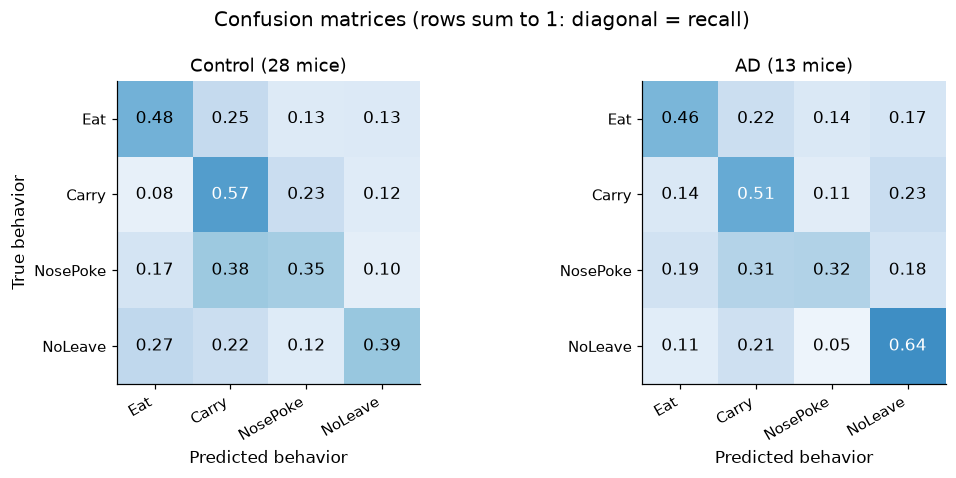

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, group in zip(axes, viz.GROUP_ORDER):
    matrix = evaluation.normalized_confusion_matrix(final_predictions[group], CLASSES)
    ax.imshow(matrix.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            value = matrix.values[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                    color="white" if value > 0.5 else "black")
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=30, ha="right")
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Predicted behavior")
    ax.set_title(f"{group} ({data_by_group[group]['Id'].nunique()} mice)")
    ax.grid(False)
axes[0].set_ylabel("True behavior")
fig.suptitle("Confusion matrices (rows sum to 1: diagonal = recall)")
fig.tight_layout()
viz.save_figure(fig, "02_confusion_matrices")
plt.show()

**How to read the output:** each row shows what happened to the trials of one true behavior. The diagonal is the recall: the fraction of trials of that behavior that were correctly predicted.
* **Eat** has high *precision* (0.83–0.84: when the model says Eat, it is usually right) but recall below 0.5. Because of the class weights, the model often moves Eat trials into the rarer classes, mostly Carry.
* **Carry vs NosePoke** are often confused (e.g. 38 % of Control NosePoke trials are predicted as Carry). Both happen mainly with **large pellets**, and nothing *before* the trial tells them apart well.
* **NoLeave is much more predictable in AD mice:** recall 0.64 and F1 0.41 in AD vs 0.39 and 0.24 in Control. AD NoLeave trials follow a pattern (long-soft condition, after NoLeave or Carry) that the model can learn. In Control mice NoLeave is rare and more scattered.
* **Carry is harder in AD** (F1 0.29 vs 0.40). AD mice carry less often, and 23 % of their Carry trials are predicted as NoLeave.

### 7.2 How much does performance vary between mice?

A single overall score can hide large differences between individual animals. For each held-out mouse we compute the balanced accuracy over the behaviors that mouse actually showed.

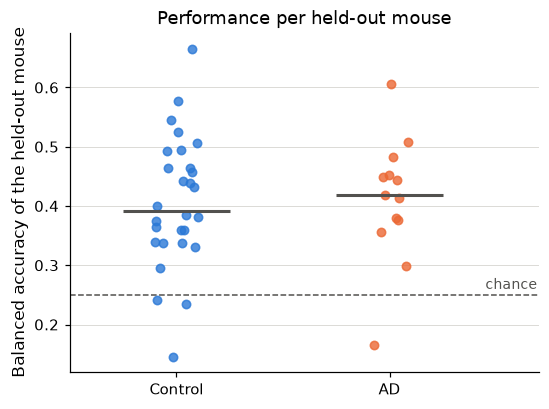

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
AD,13.0,0.41,0.11,0.17,0.38,0.42,0.45,0.61
Control,28.0,0.41,0.11,0.15,0.34,0.39,0.47,0.67


In [13]:
from sklearn.metrics import balanced_accuracy_score

per_mouse_rows = []
for group in viz.GROUP_ORDER:
    for mouse_id, trials in final_predictions[group].groupby("Id"):
        per_mouse_rows.append({
            "group": group, "Id": mouse_id, "n_trials": len(trials),
            "balanced_accuracy": balanced_accuracy_score(trials["true"], trials["predicted"]),
            "n_behaviors_shown": trials["true"].nunique(),
        })
per_mouse = pd.DataFrame(per_mouse_rows)

fig, ax = plt.subplots(figsize=(5.5, 4))
rng = np.random.default_rng(0)
for g_index, group in enumerate(viz.GROUP_ORDER):
    values = per_mouse.loc[per_mouse["group"] == group, "balanced_accuracy"]
    jitter = rng.uniform(-0.1, 0.1, size=len(values))
    ax.scatter(g_index + jitter, values, s=30, alpha=0.8, color=viz.GROUP_COLORS[group])
    ax.hlines(values.median(), g_index - 0.25, g_index + 0.25, color=viz.NEUTRAL_DARK, linewidth=2)
ax.axhline(0.25, color=viz.NEUTRAL_DARK, linestyle="--", linewidth=1)
ax.text(1.45, 0.26, "chance", fontsize=9, color=viz.NEUTRAL_DARK)
ax.set_xticks([0, 1])
ax.set_xticklabels(viz.GROUP_ORDER)
ax.set_xlim(-0.5, 1.7)
ax.set_ylabel("Balanced accuracy of the held-out mouse")
ax.set_title("Performance per held-out mouse")
viz.save_figure(fig, "02_per_mouse_performance")
plt.show()

per_mouse.groupby("group")["balanced_accuracy"].describe().round(2)

**How to read the output:** the median held-out mouse has a balanced accuracy of ~0.40 in both groups, but individual mice range from **0.15 (below chance) to 0.67**. A model trained on other mice describes some animals well and others poorly. This is the practical meaning of large between-mouse variability: the model captures the *average* mouse's decision rules, and individual mice deviate from them. (Per-mouse scores are noisy: a mouse with few trials of a class can swing its balanced accuracy a lot.)

## 8. Comparing Control and AD

So far the AD models look somewhat different from the Control models. But a direct comparison is unfair in two ways:
1. **Sample size:** Control models were trained on 27 mice, AD models on only 12. More training mice usually means better generalization.
2. **Different class balance:** the groups show the behaviors in different proportions.

### 8.1 Equal sample size: Control models trained on 13 mice

We draw 13 Control mice at random (20 times), run the same LOMO evaluation each time, and look at the distribution of scores. If AD performance falls *inside* this distribution, the AD–Control difference could be explained by sample size alone.

*To keep the run time reasonable, the regularization strength is fixed at C = 0.1 instead of being tuned in every repetition. C = 0.1 was the inner loop's most frequent choice for Control (17 of 28 folds); for AD the choice varied (0.01 in 7 of 13 folds). Fixing C hardly matters here: the AD macro-F1 is 0.400 with C fixed and 0.402 with tuning.*

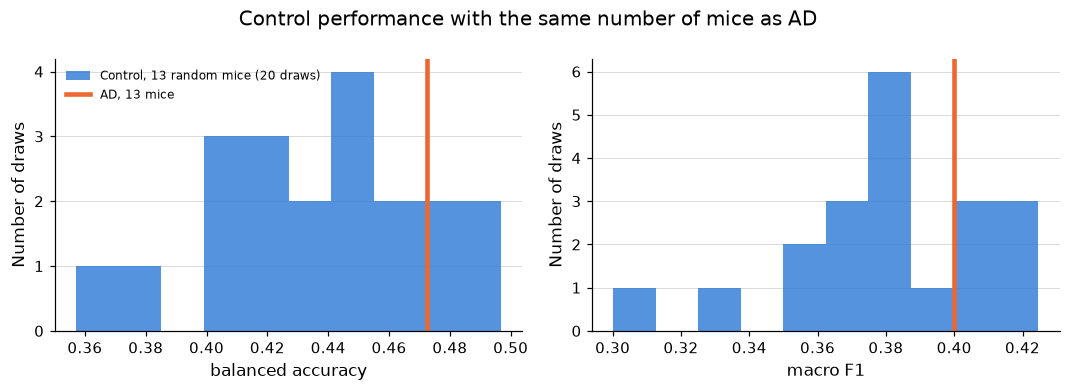

Control (13-mouse subsamples):
      balanced_accuracy  macro_F1  log_loss
mean              0.437     0.380     1.211
min               0.357     0.300     1.175
max               0.497     0.425     1.264

AD (13 mice): {'balanced_accuracy': 0.472, 'macro_F1': 0.4, 'log_loss': 1.163}


In [14]:
features = FEATURE_SETS[FINAL]
feature_columns = features["categorical"] + features["numeric"]
fixed_model, _ = modeling.make_model("Logistic regression", features["categorical"], features["numeric"])
fixed_model.set_params(classifier__C=0.1)

control_mice = data_by_group["Control"]["Id"].unique()
n_ad_mice = data_by_group["AD"]["Id"].nunique()
rng = np.random.default_rng(1)

subsample_scores = []
for repetition in range(20):
    chosen_mice = rng.choice(control_mice, size=n_ad_mice, replace=False)
    subset = data_by_group["Control"][data_by_group["Control"]["Id"].isin(chosen_mice)]
    predictions = evaluation.leave_one_mouse_out(fixed_model, {}, subset, feature_columns, "Behavior", CLASSES)
    subsample_scores.append(evaluation.summary_metrics(predictions, CLASSES))
subsample_scores = pd.DataFrame(subsample_scores)

ad_fixed = evaluation.leave_one_mouse_out(fixed_model, {}, data_by_group["AD"], feature_columns, "Behavior", CLASSES)
ad_fixed_scores = evaluation.summary_metrics(ad_fixed, CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, metric in zip(axes, ["balanced_accuracy", "macro_F1"]):
    ax.hist(subsample_scores[metric], bins=10, color=viz.GROUP_COLORS["Control"], alpha=0.8,
            label="Control, 13 random mice (20 draws)")
    ax.axvline(ad_fixed_scores[metric], color=viz.GROUP_COLORS["AD"], linewidth=3, label="AD, 13 mice")
    ax.set_xlabel(metric.replace("_", " "))
    ax.set_ylabel("Number of draws")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Control performance with the same number of mice as AD")
fig.tight_layout()
viz.save_figure(fig, "02_equal_sample_size")
plt.show()

print("Control (13-mouse subsamples):")
print(subsample_scores.describe().loc[["mean", "min", "max"]].round(3))
print("\nAD (13 mice):", {k: round(v, 3) for k, v in ad_fixed_scores.items()})

**How to read the output:** with only 13 training mice, Control performance varies a lot between random draws (balanced accuracy 0.36–0.50, macro-F1 0.30–0.43). Which mice happen to be in the sample matters a great deal. The AD score lies **within** this range, in its upper part.

**Conclusion:** at equal sample size, behavior is **about equally predictable** in AD and Control mice. We cannot claim that one group is more predictable than the other. This section also shows how unstable any single 13-mouse estimate is, an important limitation for every AD result in this project.

### 8.2 Cross-group transfer: do the two groups follow the same rules?

**Idea:** train a model on **all Control mice** and use it to predict **AD mice** (and the other way around). Compare with a model trained on the same group (the LOMO results).
* If the Control model predicts AD mice **as well as** an AD model does, the two groups follow similar feature–behavior relationships.
* If it does **worse**, the AD mice behave in ways the Control model does not expect, i.e. the relationships differ.

*Note:* the within-group LOMO model is trained on 12 or 27 mice. The transfer model uses all 28 Control mice (or all 13 AD mice). Sample size again favors the Control model, which is worth remembering when reading the result.

In [15]:
transfer_rows = []
for train_group, test_group in [("Control", "AD"), ("AD", "Control")]:
    transfer = evaluation.train_on_one_set_test_on_another(
        fixed_model, data_by_group[train_group], data_by_group[test_group], feature_columns, "Behavior", CLASSES)
    within = evaluation.leave_one_mouse_out(fixed_model, {}, data_by_group[test_group],
                                            feature_columns, "Behavior", CLASSES)
    diff = evaluation.paired_bootstrap_difference(within, transfer, CLASSES, metric="macro_F1")
    for label, preds in [(f"trained on {test_group} (LOMO)", within), (f"trained on {train_group}", transfer)]:
        row = {"tested on": test_group, "model": label}
        row.update(evaluation.summary_metrics(preds, CLASSES))
        transfer_rows.append(row)
    print(f"Tested on {test_group}: macro-F1 (transfer - within) = {diff.mean():+.3f}, "
          f"95% CI [{np.quantile(diff, 0.025):+.3f}, {np.quantile(diff, 0.975):+.3f}]")

pd.DataFrame(transfer_rows).round(3)

Tested on AD: macro-F1 (transfer - within) = -0.041, 95% CI [-0.077, +0.002]


Tested on Control: macro-F1 (transfer - within) = -0.064, 95% CI [-0.091, -0.039]


,tested on,model,balanced_accuracy,macro_F1,log_loss
0,AD,trained on AD (LOMO),0.472,0.400,1.163
1,AD,trained on Control,0.407,0.356,1.230
2,Control,trained on Control (LOMO),0.454,0.401,1.202
3,Control,trained on AD,0.381,0.337,1.258


**How to read the output:**
* **Control model → AD mice:** macro-F1 drops from 0.40 (AD's own LOMO model) to 0.36 (difference −0.04, 95 % CI −0.08 to +0.00). The Control model was trained on **more** mice (28 vs 12), yet it predicts AD mice slightly **worse** than a model trained on other AD mice. This suggests that the AD mice follow partly different rules. The evidence is borderline (the CI just touches 0).
* **AD model → Control mice:** macro-F1 drops from 0.40 to 0.34 (CI −0.09 to −0.04). But here the AD model is trained on fewer mice than the Control LOMO model (13 vs 27), so part of this drop is simply sample size.

**Interpretation:** the feature–behavior relationships are **largely shared**: a model from one group still predicts the other far above chance. There are **some group-specific patterns**, most likely the NoLeave pattern of AD mice. Notebook 04 will examine *which* relationships differ by comparing model coefficients.

### 8.3 Probabilities: class weights vs. honest probabilities

Section 4 showed something surprising: the logistic regression has a **higher (worse) log loss** than the baseline, even though it classifies much better. The reason is `class_weight="balanced"`: by making rare classes "count more" during training, the model learns to **over-predict** them. Its predicted probability of NoLeave is systematically too high. Good for finding rare classes, bad for the probabilities themselves.

There are two different goals:
* **Decisions** ("which behavior is most likely?") → class weights help (balanced accuracy, macro-F1).
* **Probabilities** ("how likely is each behavior?") → train **without** class weights, so that the probabilities match the real frequencies (*calibration*).

Let us train the same model without class weights and compare.

In [16]:
prob_rows = []
for group in viz.GROUP_ORDER:
    run("Logistic regression (unweighted)", FINAL, group)
    for model_name in ["Baseline (class frequencies)", "Logistic regression", "Logistic regression (unweighted)"]:
        key = (group, FINAL if model_name != "Baseline (class frequencies)" else "Task", model_name)
        row = {"group": group, "model": model_name}
        row.update(evaluation.summary_metrics(all_predictions[key], CLASSES))
        prob_rows.append(row)
pd.DataFrame(prob_rows).round(3)

,group,model,balanced_accuracy,macro_F1,log_loss
0,Control,Baseline (class frequencies),0.250,0.186,1.114
1,Control,Logistic regression,0.450,0.398,1.205
2,Control,Logistic regression (unweighted),0.332,0.331,0.973
3,AD,Baseline (class frequencies),0.250,0.194,1.105
4,AD,Logistic regression,0.482,0.402,1.185
5,AD,Logistic regression (unweighted),0.371,0.391,0.941


**Calibration plot.** For the unweighted model we group trials by their predicted probability for a class (e.g. "predicted P(Carry) between 0.2 and 0.3") and check how often that class *actually* occurred. A well-calibrated model lies on the diagonal: among trials with a predicted 30 % chance of Carry, about 30 % are Carry.

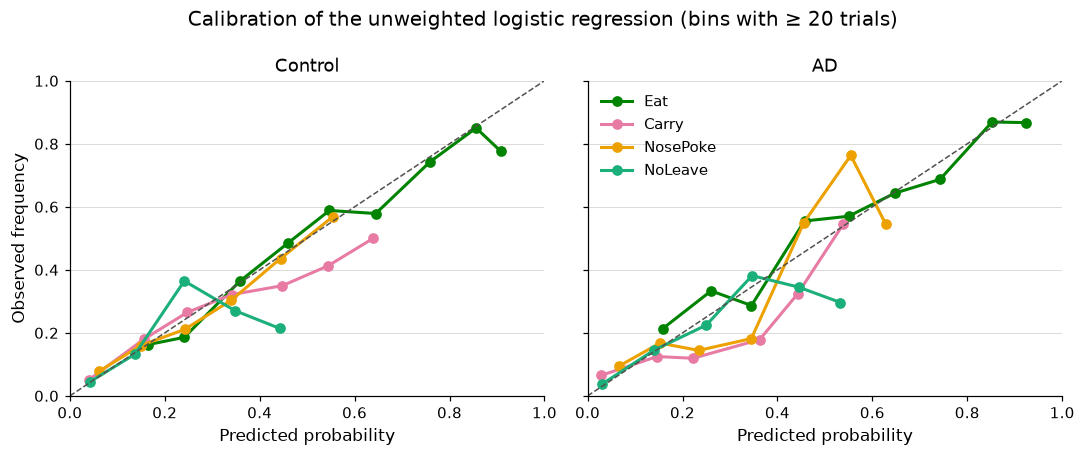

In [17]:
bins = np.linspace(0, 1, 11)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, group in zip(axes, viz.GROUP_ORDER):
    predictions = all_predictions[(group, FINAL, "Logistic regression (unweighted)")]
    for behavior in CLASSES:
        predicted = predictions[behavior]
        actual = (predictions["true"] == behavior).astype(float)
        bin_index = np.digitize(predicted, bins) - 1
        x, y = [], []
        for b in range(len(bins) - 1):
            in_bin = bin_index == b
            if in_bin.sum() >= 20:          # skip bins with too few trials to be reliable
                x.append(predicted[in_bin].mean())
                y.append(actual[in_bin].mean())
        ax.plot(x, y, marker="o", linewidth=2, color=viz.BEHAVIOR_COLORS[behavior], label=behavior)
    ax.plot([0, 1], [0, 1], linestyle="--", color=viz.NEUTRAL_DARK, linewidth=1)
    ax.set_xlabel("Predicted probability")
    ax.set_title(group)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Observed frequency")
axes[1].legend()
fig.suptitle("Calibration of the unweighted logistic regression (bins with ≥ 20 trials)")
fig.tight_layout()
viz.save_figure(fig, "02_calibration")
plt.show()

**How to read the output:**
* **Log loss:** the unweighted model has a clearly **lower (better) log loss than the baseline** (0.97 vs 1.11 Control, 0.94 vs 1.11 AD). So the features do contain real probabilistic information. The weighted model hid this because its probabilities were distorted. The price: balanced accuracy drops (0.45 → 0.33 Control), because an unweighted model rarely predicts rare classes.
* **Calibration:** for Eat, NosePoke and Carry at low-to-moderate probabilities, the curves lie close to the diagonal, so the predicted probabilities can be read as real frequencies. Two deviations: in Control, **Carry** is slightly over-predicted at higher probabilities (predicted 0.6 → observed 0.5), and **NoLeave** is poorly calibrated above ~0.3 in both groups (few trials reach such probabilities, so these points are noisy). AD curves are noisier overall because there are fewer trials.

**Which model to use?** It depends on the question. To *classify* trials or compare per-class recall → weighted model. To *estimate probabilities* (e.g. "how likely is NoLeave in long-soft?") → unweighted model.

## 9. The food-site decision: does the approach behavior add information?

**Question:** once a mouse has left home, can *how it approaches the food* help predict what it will do there (Eat, Carry or NosePoke)?

**Why this is a valid (prospective) question:** two variables are measured on the way to the food, i.e. **before** the food-site decision:
* `DelayToStart`: how long the mouse waited at home after the gate opened (seconds),
* `InitialVelOut`: its speed at the start of the outbound trip (cm/s).

**Set-up:**
* Only trials in which the mouse **left home**, so three classes (chance level of balanced accuracy = 1/3). NoLeave trials must be excluded: their approach variables do not exist, and a model would learn "missing value = NoLeave" (leakage). Also, `DelayToStart` partly *defines* NoLeave (the 3-minute time-out).
* We compare the model from sections 4–7 (task + history + experience) **with and without** the two approach variables, on exactly the same trials.
* Preprocessing inside the pipeline: median imputation for the ~2 % ordinary missing values (fitted on the training mice only), a `log1p` transform for the right-skewed variables, and standardization.

**Interpretation caveat:** approach behavior may *reflect* a choice the mouse has already made at home (e.g. it runs fast *because* it intends to carry). So these variables are best understood as **early markers** of the decision, not as its causes.

#### Why not `OutboundVel`?
`OutboundVel` is averaged over **all** outbound trips of a trial. In trials with back-and-forth movement it therefore includes trips made *after* the mouse first reached the food. One might restrict the analysis to trials without back-and-forth, but the table below shows why that would bias the result: back-and-forth depends strongly on the behavior itself.

In [18]:
left_home = df[df["Behavior"] != "NoLeave"]
has_back_and_forth = (left_home["BackAndForth"] > 0).map({True: "≥ 1 back-and-forth", False: "none"})
pd.crosstab(has_back_and_forth, left_home["Behavior"], normalize="columns")[["Eat", "Carry", "NosePoke"]].round(2)

Behavior,Eat,Carry,NosePoke
BackAndForth,,,
none,0.7,0.96,0.79
≥ 1 back-and-forth,0.3,0.04,0.21


**How to read the output:** about 30 % of Eat trials but only ~4 % of Carry trials contain back-and-forth movement. Keeping only trials without back-and-forth would remove a third of the Eat trials, selected by something that happens *after* the decision. Such outcome-dependent selection biases the comparison, so `OutboundVel` is not used at all.

In [19]:
FOOD_CLASSES = ["Eat", "Carry", "NosePoke"]
APPROACH = ["DelayToStart", "InitialVelOut"]
base_categorical = FEATURE_SETS[FINAL]["categorical"]
base_numeric = FEATURE_SETS[FINAL]["numeric"]

food_sets = {
    "Task + History + Experience": base_numeric,
    "+ Approach (DelayToStart, InitialVelOut)": base_numeric + APPROACH,
}

food_rows = []
food_predictions = {}
for group in viz.GROUP_ORDER:
    moved = data_by_group[group][data_by_group[group]["Behavior"].isin(FOOD_CLASSES)]
    for set_name, numeric in food_sets.items():
        pipeline, grid = modeling.make_model("Logistic regression", base_categorical, numeric,
                                             log_transform=True)
        predictions = evaluation.leave_one_mouse_out(pipeline, grid, moved, base_categorical + numeric,
                                                     "Behavior", FOOD_CLASSES)
        food_predictions[(group, set_name)] = predictions
        scores = evaluation.summary_metrics(predictions, FOOD_CLASSES)
        boot = evaluation.bootstrap_over_mice(predictions, FOOD_CLASSES)
        row = {"group": group, "features": set_name}
        for metric in ["balanced_accuracy", "macro_F1", "log_loss"]:
            row[metric] = scores[metric]
            row[metric + "_CI"] = f"[{boot[metric].quantile(0.025):.2f}, {boot[metric].quantile(0.975):.2f}]"
        food_rows.append(row)

food_table = pd.DataFrame(food_rows)
food_table.round(3)

,group,features,balanced_accuracy,balanced_accuracy_CI,macro_F1,macro_F1_CI,log_loss,log_loss_CI
0,Control,Task + History + Experience,0.530,"[0.50, 0.56]",0.494,"[0.43, 0.54]",0.932,"[0.91, 0.95]"
1,Control,"+ Approach (DelayToStart, InitialVelOut)",0.520,"[0.48, 0.55]",0.489,"[0.44, 0.52]",0.907,"[0.87, 0.95]"
2,AD,Task + History + Experience,0.504,"[0.42, 0.54]",0.426,"[0.35, 0.48]",0.966,"[0.93, 1.00]"
3,AD,"+ Approach (DelayToStart, InitialVelOut)",0.532,"[0.45, 0.57]",0.454,"[0.36, 0.50]",0.929,"[0.86, 1.02]"


*Note on the code:* `log_transform=True` applies `log1p` to **all** numeric columns, including `TrialInSession` and `SessionInCondition`, in **both** models. Both models are therefore treated identically, and the only difference between them is the two approach variables. For small positive counts the transform is harmless (it only compresses larger values).

**Paired comparison** (same mice, same trials; as in section 5):

In [20]:
food_paired = []
for group in viz.GROUP_ORDER:
    without = food_predictions[(group, "Task + History + Experience")]
    with_approach = food_predictions[(group, "+ Approach (DelayToStart, InitialVelOut)")]
    for metric in ["balanced_accuracy", "macro_F1"]:
        diff = evaluation.paired_bootstrap_difference(without, with_approach, FOOD_CLASSES, metric=metric)
        food_paired.append({
            "group": group, "metric": metric,
            "mean difference (with − without approach)": diff.mean(),
            "95% CI": f"[{np.quantile(diff, 0.025):+.3f}, {np.quantile(diff, 0.975):+.3f}]",
            "fraction of bootstraps > 0": (diff > 0).mean(),
        })
pd.DataFrame(food_paired).round(3)

,group,metric,mean difference (with − without approach),95% CI,fraction of bootstraps > 0
0,Control,balanced_accuracy,-0.011,"[-0.032, +0.013]",0.165
1,Control,macro_F1,-0.006,"[-0.030, +0.019]",0.313
2,AD,balanced_accuracy,0.030,"[-0.029, +0.094]",0.819
3,AD,macro_F1,0.027,"[-0.019, +0.076]",0.857


In [21]:
for group in viz.GROUP_ORDER:
    print(group)
    print(evaluation.per_class_table(food_predictions[(group, "+ Approach (DelayToStart, InitialVelOut)")],
                                     FOOD_CLASSES).round(2))
    print()

Control
          precision  recall    F1  n_trials
Eat            0.84    0.60  0.70      2030
Carry          0.35    0.58  0.44       610
NosePoke       0.29    0.37  0.32       567

AD
          precision  recall    F1  n_trials
Eat            0.84    0.54  0.66      1240
Carry          0.30    0.68  0.41       207
NosePoke       0.24    0.38  0.29       298



**How to read the output:**
* **Without the approach variables**, the food-site decision is predicted with a balanced accuracy of ~0.50–0.53 (chance 0.33).
* **Adding `DelayToStart` and `InitialVelOut` changes little:**
  * Control: −0.01 balanced accuracy (95 % CI −0.03 to +0.01), i.e. no gain;
  * AD: +0.03 (CI −0.03 to +0.09), a possible small gain, but uncertain with 13 mice;
  * log loss improves slightly in both groups (0.93 → 0.91 Control, 0.97 → 0.93 AD), so the predicted *probabilities* become a little more accurate even though the final answers hardly change.
* Per class, Eat is recognized best (F1 ≈ 0.66–0.70), while Carry and NosePoke remain hard to separate (F1 ≈ 0.3–0.4).

**Why so little, when Carry trials clearly start later (notebook 01: median delay ≈ 11 s for Carry vs ≈ 3 s for Eat)?** Two reasons:
1. **Overlap with existing features.** Long delays occur mostly with large pellets, in long-distance sessions and after NoLeave or Carry trials, all of which the model already knows. The approach adds little *new* information.
2. **Between-mouse differences.** Much of the variation in delay is between animals (notebook 01, section 10.3: some mice are hesitant in general). A model tested on a *new* mouse cannot use "this mouse is slow" to infer anything about its choices.

**Conclusion:** how a mouse approaches the food is only a weak early marker of what it will do there, once the task situation and the recent history are known. The food-site decision seems to depend mainly on the pellet (size) and on the mouse's recent behavior, not on approach speed.

## 10. Save results

In [22]:
results_table = show(all_rows)
results_table.to_csv(f"{TABLES}/02_behavior_classification_results.csv", index=False)
per_class.round(3).to_csv(f"{TABLES}/02_per_class_metrics.csv")
food_table.round(3).to_csv(f"{TABLES}/02_food_site_decision_results.csv", index=False)

# Per-behavior recall and F1 for EVERY model and feature set (used for the README heatmap)
per_class_rows = []
for (group, feature_set, model_name), predictions in all_predictions.items():
    table = evaluation.per_class_table(predictions, CLASSES)
    for behavior in CLASSES:
        per_class_rows.append({"group": group, "features": feature_set, "model": model_name,
                               "behavior": behavior, "recall": table.loc[behavior, "recall"],
                               "F1": table.loc[behavior, "F1"]})
pd.DataFrame(per_class_rows).round(3).to_csv(f"{TABLES}/02_per_class_all_models.csv", index=False)
results_table

,group,features,model,balanced_accuracy,balanced_accuracy_CI,macro_F1,macro_F1_CI,log_loss,log_loss_CI
0,Control,Task,Baseline (class frequencies),0.250,"[0.25, 0.25]",0.186,"[0.17, 0.20]",1.114,"[0.99, 1.24]"
1,Control,Task,Logistic regression,0.416,"[0.36, 0.46]",0.389,"[0.33, 0.44]",1.282,"[1.25, 1.31]"
2,AD,Task,Baseline (class frequencies),0.250,"[0.25, 0.25]",0.194,"[0.17, 0.21]",1.105,"[0.92, 1.30]"
3,AD,Task,Logistic regression,0.405,"[0.37, 0.44]",0.311,"[0.24, 0.37]",1.278,"[1.23, 1.32]"
4,Control,Task + History,Logistic regression,0.431,"[0.40, 0.45]",0.378,"[0.34, 0.41]",1.207,"[1.18, 1.24]"
5,Control,Task + History + Experience,Logistic regression,0.450,"[0.42, 0.47]",0.398,"[0.36, 0.43]",1.205,"[1.18, 1.23]"
6,AD,Task + History,Logistic regression,0.466,"[0.40, 0.51]",0.390,"[0.32, 0.44]",1.180,"[1.14, 1.22]"
7,AD,Task + History + Experience,Logistic regression,0.482,"[0.44, 0.51]",0.402,"[0.33, 0.45]",1.185,"[1.15, 1.22]"
8,Control,Task + History + Experience,Decision tree,0.441,"[0.40, 0.48]",0.397,"[0.35, 0.44]",1.280,"[1.21, 1.38]"
9,Control,Task + History + Experience,Random forest,0.445,"[0.42, 0.47]",0.393,"[0.35, 0.43]",1.202,"[1.18, 1.23]"


## 11. Summary

### Answers to the research questions

**1. Can behavior be predicted prospectively?** Partly. Using only information available before the trial, the best models reach a balanced accuracy of **~0.45–0.50** (chance 0.25) on unseen mice. Pellet size, distance and texture explain a meaningful but limited part of the choice. Large differences between individual mice limit what any model can achieve.

**Food-site decision (section 9):** among trials where the mouse left home, the choice between Eat, Carry and NosePoke is predicted with a balanced accuracy of ~0.50–0.53 (chance 0.33). Adding the approach behavior (`DelayToStart`, `InitialVelOut`) adds little or nothing (Control −0.01; AD +0.03, uncertain).

**2. Does it generalize to unseen mice?** Yes, above chance for nearly all held-out mice, but with large variation between animals (balanced accuracy 0.15–0.67 per mouse).

**3. Do Control and AD differ?**
* At equal sample size, overall predictability is **similar** (section 8.1).
* **Behavioral history matters more in AD** mice (+0.07 macro-F1 vs ~0 in Control).
* **NoLeave is much more predictable in AD**, Carry is less predictable.
* A Control-trained model predicts AD mice somewhat worse than an AD-trained model (borderline evidence), so the feature–behavior relationships are **largely shared, with some group-specific patterns**.

### Methodological lessons
| Observation | Lesson |
|---|---|
| Flexible models ≈ logistic regression | Complexity does not help when the features are few and the main variation is between animals |
| Weighted model: good balanced accuracy, bad log loss | Class weights improve decisions but distort probabilities. Use an unweighted model for probabilities |
| Movement measured during/after the behavior (time at food, inbound speed, back-and-forth) differs strongly by outcome | These variables are consequences of the behavior. Using them as predictors would be target leakage, so no model uses them |
| Back-and-forth occurs mostly in Eat trials | Selecting trials by a post-decision variable biases the comparison. `OutboundVel` (which mixes in later trips) was excluded rather than restricted |
| AD results vary a lot with the sample (13 mice) | Report uncertainty (bootstrap over mice) and avoid over-interpreting small differences |
| `log_loss` silently assumes alphabetical class order | Always check the column order of predicted probabilities |

### Limitations
* **Correlational, not causal.** A feature being predictive does not mean it *causes* the behavior. In particular, condition effects are partly confounded with the block order of the experiment (notebook 01, section 3.5).
* **13 AD mice:** all AD estimates have wide uncertainty.
* Coverage is unbalanced (13 mice never received hard food), so texture effects are learned from a subset of mice.

**Next:** notebook 03 asks the reverse question, whether behavior can tell us if a mouse is Control or AD. Notebook 04 interprets *which* features drive the predictions and how the relationships differ between groups.